## 1. Install WFDB

Installs the WFDB Python package, which provides tools for downloading and reading PhysioNet ECG records and their annotation files. The `-q` flag reduces installation output. Run this cell before importing `wfdb` in a fresh Colab runtime.


In [ ]:
!pip -q install wfdb

## 2. Import libraries and check the runtime

Imports the libraries used throughout the notebook: NumPy/Pandas for data handling, Matplotlib for plots, WFDB for ECG data, SciPy for signal filtering, scikit-learn for splitting/encoding/metrics, and TensorFlow/Keras for the neural network. The final lines report the TensorFlow version and whether a GPU is available.


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wfdb

from scipy.signal import butter, filtfilt
from scipy.ndimage import uniform_filter1d

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout,
    Concatenate
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam

print("TensorFlow:", tf.__version__)
print("Num GPUs:", len(tf.config.list_physical_devices('GPU')))

TensorFlow: 2.20.0
Num GPUs: 1


## 3. Set random seeds

Sets the random seeds for NumPy, Python's `random`, and TensorFlow, and sets Python's hash seed. This improves repeatability when operations use randomness, although exact results can still vary across hardware and software versions.


In [ ]:
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

print("Seed:", SEED)

Seed: 42


## 4. Download MIT-BIH records

Defines the MIT-BIH Arrhythmia Database record IDs used by this experiment and attempts to download each record into the local `mitdb` folder. The exception handler skips records whose download fails; therefore, check the resulting files/logs if a complete dataset is required.


In [ ]:
records = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

print("Number of records:", len(records))

for record in records:
    try:
        wfdb.dl_database(
            'mitdb',
            dl_dir='mitdb',
            records=[record]
        )
    except:
        pass

print("Dataset download completed.")

Number of records: 48
Generating record list for: 100
Generating list of all files for: 100
Finished downloading files
Generating record list for: 101
Generating list of all files for: 101
Finished downloading files
Generating record list for: 102
Generating list of all files for: 102
Finished downloading files
Generating record list for: 103
Generating list of all files for: 103
Finished downloading files
Generating record list for: 104
Generating list of all files for: 104
Finished downloading files
Generating record list for: 105
Generating list of all files for: 105
Finished downloading files
Generating record list for: 106
Generating list of all files for: 106
Finished downloading files
Generating record list for: 107
Generating list of all files for: 107
Finished downloading files
Generating record list for: 108
Generating list of all files for: 108
Finished downloading files
Generating record list for: 109
Generating list of all files for: 109
Finished downloading files
Generati

## 5. Map annotation symbols to five AAMI classes

Maps individual MIT-BIH beat annotation symbols into the five target categories used by this model: N (normal and related), S (supraventricular ectopic), V (ventricular ectopic), F (fusion), and Q (unknown/paced or other). `CLASS_NAMES` records the class labels for plots and reporting. This mapping determines the labels the model learns.


In [ ]:
AAMI_MAP = {
    # N class
    'N': 'N',
    'L': 'N',
    'R': 'N',
    'e': 'N',
    'j': 'N',

    # S class
    'A': 'S',
    'a': 'S',
    'J': 'S',
    'S': 'S',

    # V class
    'V': 'V',
    'E': 'V',

    # F class
    'F': 'F',

    # Q class
    '/': 'Q',
    'f': 'Q',
    'Q': 'Q'
}

CLASS_NAMES = ['N', 'S', 'V', 'F', 'Q']

print(AAMI_MAP)

{'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F', '/': 'Q', 'f': 'Q', 'Q': 'Q'}


## 6. Define ECG signal filtering

Defines a Butterworth band-pass filter and a smoothing function. The band-pass filter keeps frequencies between `LOWCUT` and `HIGHCUT` Hz at the assumed 360 Hz sampling rate, while reducing slower baseline drift and higher-frequency noise. `filtfilt` applies the filter forward and backward to avoid phase shift; `uniform_filter1d` performs moving-window smoothing.


In [ ]:
FS = 360

LOWCUT = 2.0
HIGHCUT = 26.0

def bandpass_filter(signal, fs=360, lowcut=2.0, highcut=26.0, order=3):
    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(order, [low, high], btype='band')

    filtered = filtfilt(b, a, signal)

    return filtered


def smooth_signal(signal, window=21):
    return uniform_filter1d(signal, size=window)

## 7. Normalize beats and extract annotated heartbeats

Sets each beat window to 180 samples, with 90 samples on either side of the annotated beat location. For each record, the function reads the ECG and annotations, uses the first signal channel (commented as Lead II), filters and smooths the signal, then extracts a fixed-length window around each recognized annotation. Boundary windows and unexpected lengths are skipped. Each beat is min-max normalized to [0, 1]; near-constant beats become zeros. Errors are caught and reported for that record.


In [ ]:
BEAT_LENGTH = 180
HALF_BEAT = 90

def normalize_beat(beat):
    """
    Min-max normalization to [0,1].
    """
    min_val = np.min(beat)
    max_val = np.max(beat)

    if max_val - min_val < 1e-8:
        return np.zeros_like(beat)

    return (beat - min_val) / (max_val - min_val)


def extract_beats_from_record(record):
    record_path = f"mitdb/{record}"

    try:
        signal, fields = wfdb.rdsamp(record_path)

        # Lead II
        ecg = signal[:, 0]

        # MIT-BIH annotations
        annotation = wfdb.rdann(
            record_path,
            'atr'
        )

        samples = annotation.sample
        symbols = annotation.symbol

        # Filtering
        filtered = bandpass_filter(
            ecg,
            fs=FS,
            lowcut=LOWCUT,
            highcut=HIGHCUT
        )

        filtered = smooth_signal(
            filtered,
            window=21
        )

        beats = []
        labels = []

        for sample, symbol in zip(samples, symbols):

            if symbol not in AAMI_MAP:
                continue

            start = sample - HALF_BEAT
            end = sample + HALF_BEAT

            # Ignore boundary beats
            if start < 0 or end > len(filtered):
                continue

            beat = filtered[start:end]

            if len(beat) != BEAT_LENGTH:
                continue

            beat = normalize_beat(beat)

            beats.append(beat)
            labels.append(AAMI_MAP[symbol])

        return np.array(beats, dtype=np.float32), np.array(labels)

    except Exception as e:
        print(f"Error processing {record}: {e}")
        return np.empty((0, BEAT_LENGTH), dtype=np.float32), np.array([])

## 8. Build the complete beat dataset

Runs the extraction function for every requested record and collects the resulting ECG beats, mapped labels, and source-record IDs. `X` contains the beat waveforms, `y` contains their five-class labels, and `record_ids` tracks which record each beat came from. The printed shapes and record count are sanity checks on the dataset created.


In [ ]:
all_beats = []
all_labels = []
all_records = []

for i, record in enumerate(records):

    print(
        f"[{i+1:02d}/{len(records)}] "
        f"Processing record {record}..."
    )

    beats, labels = extract_beats_from_record(record)

    if len(beats) > 0:

        all_beats.append(beats)
        all_labels.append(labels)

        all_records.extend([record] * len(labels))

X = np.concatenate(all_beats, axis=0)
y = np.concatenate(all_labels, axis=0)
record_ids = np.array(all_records)

print("\nDataset created")
print("----------------")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Records:", len(np.unique(record_ids)))

[01/48] Processing record 100...
[02/48] Processing record 101...
[03/48] Processing record 102...
[04/48] Processing record 103...
[05/48] Processing record 104...
[06/48] Processing record 105...
[07/48] Processing record 106...
[08/48] Processing record 107...
[09/48] Processing record 108...
[10/48] Processing record 109...
[11/48] Processing record 111...
[12/48] Processing record 112...
[13/48] Processing record 113...
[14/48] Processing record 114...
[15/48] Processing record 115...
[16/48] Processing record 116...
[17/48] Processing record 117...
[18/48] Processing record 118...
[19/48] Processing record 119...
[20/48] Processing record 121...
[21/48] Processing record 122...
[22/48] Processing record 123...
[23/48] Processing record 124...
[24/48] Processing record 200...
[25/48] Processing record 201...
[26/48] Processing record 202...
[27/48] Processing record 203...
[28/48] Processing record 205...
[29/48] Processing record 207...
[30/48] Processing record 208...
[31/48] Pr

## 9. Inspect class imbalance

Counts how many extracted beats belong to each class and plots those counts in the predefined class order. This reveals whether some arrhythmia categories have far fewer examples than others, which is important when choosing a training strategy and interpreting metrics.


N    90608
Q     8042
V     7235
S     2781
F      802
Name: count, dtype: int64


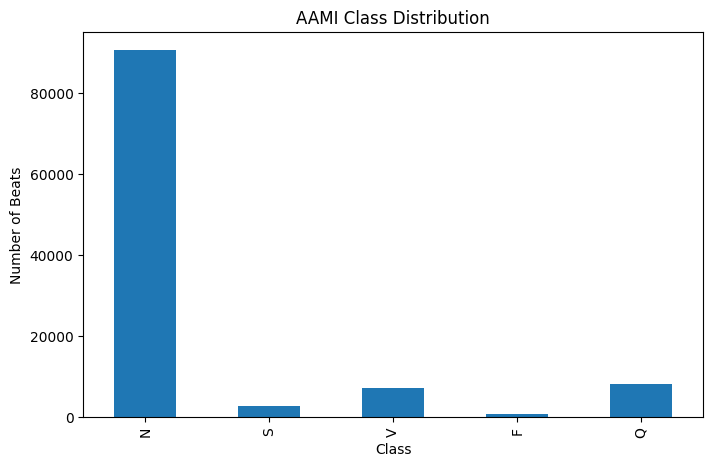

In [ ]:
distribution = pd.Series(y).value_counts()

print(distribution)

plt.figure(figsize=(8,5))

distribution.reindex(CLASS_NAMES).plot(kind='bar')

plt.title("AAMI Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Beats")

plt.show()

## 10. Visualize example ECG beats

Plots one example waveform for each class that has at least one example. The horizontal axis is the sample index within the 180-sample beat and the vertical axis is its normalized signal amplitude. This is a visual sanity check of the extracted examples, not a model evaluation.


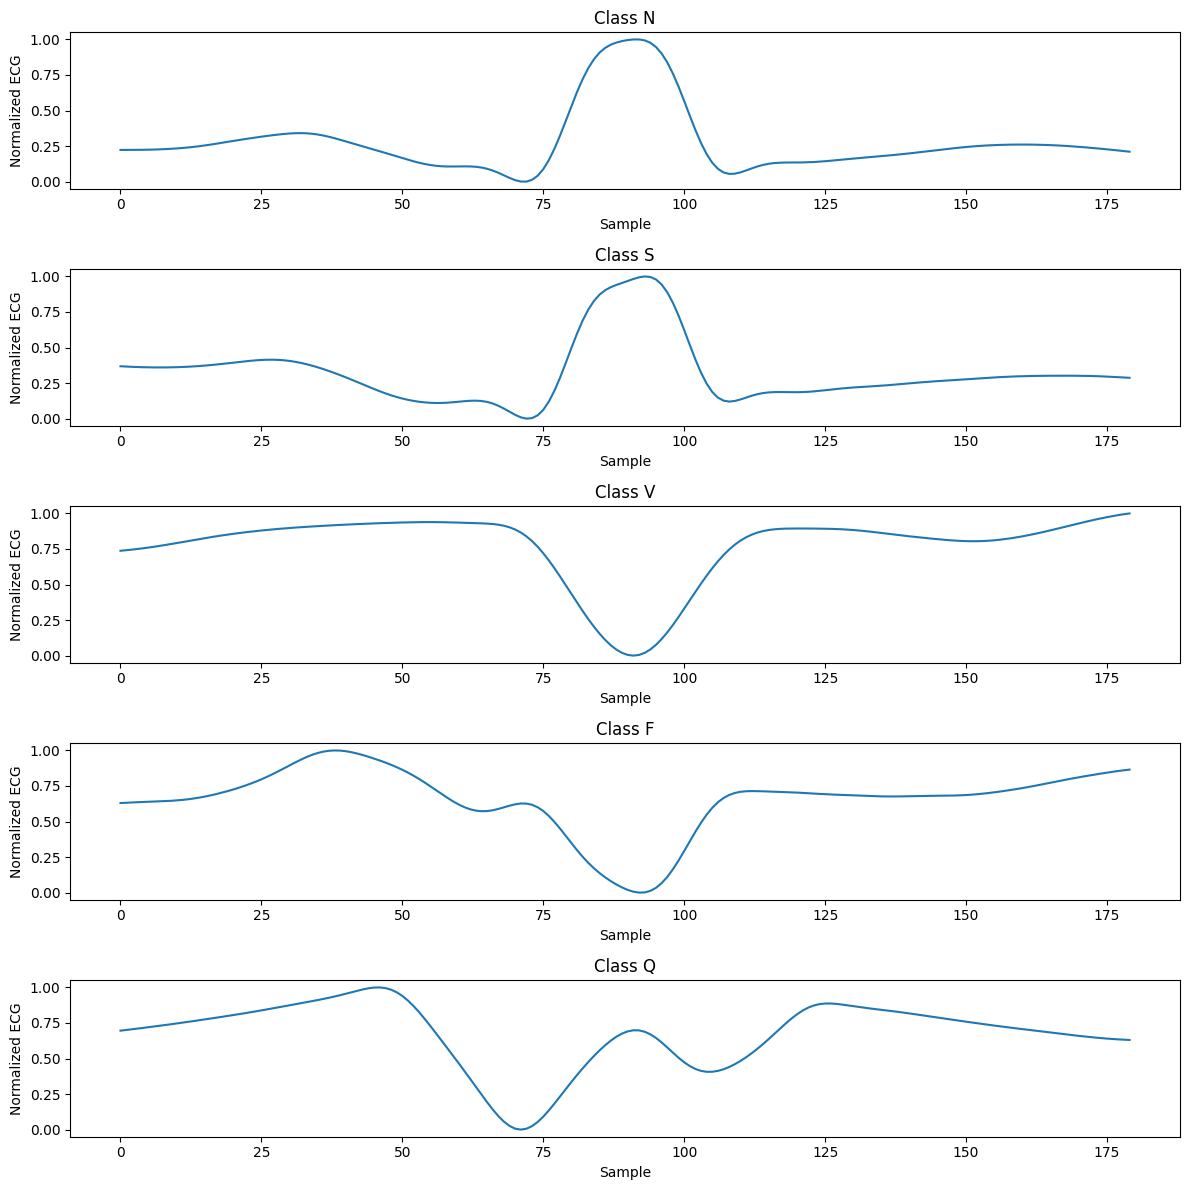

In [ ]:
# ==========================================
# V2 - VISUALIZE ECG EXAMPLES
# ==========================================

fig, axes = plt.subplots(
    5,
    1,
    figsize=(12, 12)
)

for i, cls in enumerate(CLASS_NAMES):

    indices = np.where(y == cls)[0]

    if len(indices) == 0:
        continue

    idx = indices[0]

    axes[i].plot(X[idx])

    axes[i].set_title(
        f"Class {cls}"
    )

    axes[i].set_xlabel("Sample")
    axes[i].set_ylabel("Normalized ECG")

plt.tight_layout()
plt.show()

## 11. Encode class labels as integers

Uses `LabelEncoder` to convert the string labels into integer IDs required by the model's sparse categorical loss. The printed mapping is important: later integer predictions must be interpreted using this same fitted encoder.


In [ ]:
# ==========================================
# V2 - LABEL ENCODING
# ==========================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")

for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

Class mapping:
0 -> F
1 -> N
2 -> Q
3 -> S
4 -> V


## 12. Prepare the model input shape

Converts `X` to `float32`, then adds a final channel dimension when the data is two-dimensional. The expected CNN-LSTM input is `(number_of_beats, 180, 1)`: 180 time samples and one ECG channel per beat.


In [ ]:
# ==========================================
# V2 - STANDARDIZE INPUT SHAPE
# ==========================================

X = np.asarray(
    X,
    dtype=np.float32
)

print("Shape before:", X.shape)

# If X is (N, 180), convert to (N, 180, 1)
if X.ndim == 2:

    X = X[..., np.newaxis]

print("Shape after:", X.shape)

Shape before: (109468, 180)
Shape after: (109468, 180, 1)


## 13. Split data into training, validation, and test sets

Creates a 60% training split and divides the remaining 40% equally into validation and test sets, giving approximately 60/20/20 overall. `stratify` preserves class proportions as closely as possible, and `SEED` makes the split reproducible. Note: this is a beat-level split, not a record-independent split, so beats from the same patient record may occur in multiple subsets.


In [ ]:
# ==========================================
# V2 - TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.40,
    random_state=SEED,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print()
print("Labels:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

Training: (65680, 180, 1)
Validation: (21894, 180, 1)
Testing: (21894, 180, 1)

Labels:
Train: (65680,)
Validation: (21894,)
Test: (21894,)


## 14. Verify the split shapes

Prints the shapes of the three data subsets and one example from each. Each individual sample should have shape `(180, 1)`, while each subset contains many such samples. These checks help catch shape mismatches before training.


In [ ]:
# ==========================================
# V2 - SHAPE CHECK
# ==========================================

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print()

print("Single training sample:",
      X_train[0].shape)

print("Single validation sample:",
      X_val[0].shape)

print("Single test sample:",
      X_test[0].shape)

X_train: (65680, 180, 1)
X_val  : (21894, 180, 1)
X_test : (21894, 180, 1)

Single training sample: (180, 1)
Single validation sample: (180, 1)
Single test sample: (180, 1)


## 15. Review training class counts

Counts integer-encoded labels in the training subset and converts each ID back to its class name for readable output. This confirms the class imbalance in the training data before augmentation and balanced sampling.


In [ ]:
# ==========================================
# V2 - TRAINING DISTRIBUTION
# ==========================================

train_distribution = pd.Series(
    y_train
).value_counts().sort_index()

print("Training distribution:")
print()

for class_id, count in train_distribution.items():

    class_name = label_encoder.inverse_transform(
        [class_id]
    )[0]

    print(
        f"{class_name}: {count:,}"
    )

Training distribution:

F: 481
N: 54,364
Q: 4,825
S: 1,669
V: 4,341


## 16. Define ECG data augmentation

Defines random, training-time variations for one beat: small amplitude scaling, low-level Gaussian noise, a shift of up to five samples, and a small baseline offset. Values are clipped to [0, 1], and the output is reshaped to `(180, 1)`. Augmentation creates varied training examples; it does not add independently collected ECG recordings.


In [ ]:
# ==========================================
# V2 - ECG AUGMENTATION
# ==========================================

def augment_ecg(beat):

    # Convert to numpy float32
    beat = np.asarray(
        beat,
        dtype=np.float32
    )

    # IMPORTANT:
    # Internally work with 1-D ECG
    beat = beat.reshape(-1)

    # --------------------------------------
    # 1. Amplitude scaling
    # --------------------------------------

    scale = np.random.uniform(
        0.90,
        1.10
    )

    beat = beat * scale

    # --------------------------------------
    # 2. Small Gaussian noise
    # --------------------------------------

    noise_std = np.random.uniform(
        0.002,
        0.008
    )

    noise = np.random.normal(
        0,
        noise_std,
        size=beat.shape
    ).astype(np.float32)

    beat = beat + noise

    # --------------------------------------
    # 3. Small temporal shift
    # --------------------------------------

    shift = np.random.randint(
        -5,
        6
    )

    if shift > 0:

        beat = np.concatenate([
            np.zeros(
                shift,
                dtype=np.float32
            ),
            beat[:-shift]
        ])

    elif shift < 0:

        shift_abs = abs(shift)

        beat = np.concatenate([
            beat[shift_abs:],
            np.zeros(
                shift_abs,
                dtype=np.float32
            )
        ])

    # --------------------------------------
    # 4. Small baseline variation
    # --------------------------------------

    baseline = np.random.uniform(
        -0.01,
        0.01
    )

    beat = beat + baseline

    # --------------------------------------
    # 5. Keep normalized range
    # --------------------------------------

    beat = np.clip(
        beat,
        0.0,
        1.0
    )

    # --------------------------------------
    # IMPORTANT
    # Return exactly (180,1)
    # --------------------------------------

    return beat.reshape(
        180,
        1
    ).astype(np.float32)

## 17. Wrap augmentation for TensorFlow datasets

Adapts the NumPy-based augmentation function for use inside a `tf.data` pipeline with `tf.numpy_function`. Since TensorFlow cannot automatically infer the output dimensions of that wrapper, `set_shape((180, 1))` explicitly restores the known sample shape. The label `y` is returned unchanged.


In [ ]:
# ==========================================
# V2 - TENSORFLOW AUGMENTATION WRAPPER
# ==========================================

def tf_augment_ecg(x, y):

    x = tf.numpy_function(
        augment_ecg,
        [x],
        tf.float32
    )

    # Explicitly tell TensorFlow the shape
    x.set_shape(
        (180, 1)
    )

    return x, y

## 18. Check augmentation output dimensions

Applies augmentation to one training sample and prints the original and augmented shapes. This is a quick shape check; it does not measure whether the augmentation improves model accuracy.


In [ ]:
# ==========================================
# V2 - TEST AUGMENTATION
# ==========================================

sample = X_train[0]

print(
    "Original shape:",
    sample.shape
)

augmented_sample = augment_ecg(
    sample
)

print(
    "Augmented shape:",
    augmented_sample.shape
)

Original shape: (180, 1)
Augmented shape: (180, 1)


## 19. Compare original and augmented ECG

Plots the original training beat alongside one augmented version. Use this to visually check that the transformation introduces modest variation while retaining a recognizable waveform.


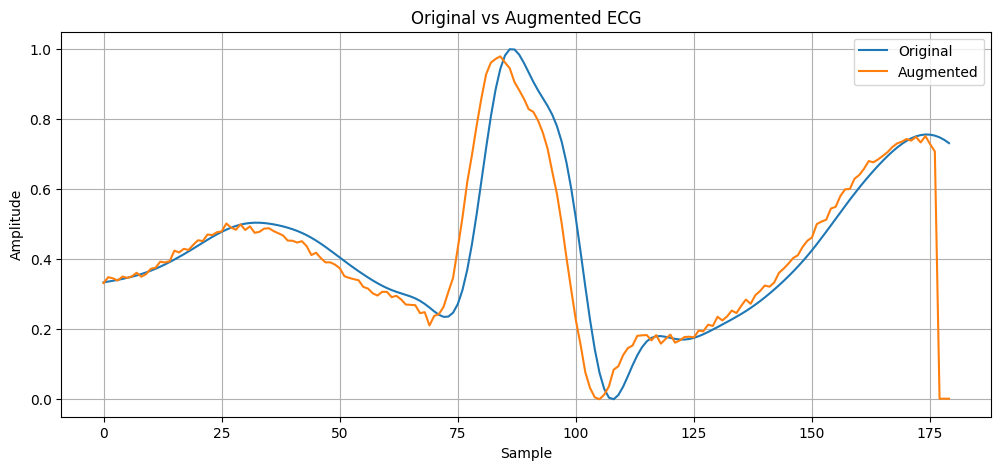

In [ ]:
# ==========================================
# V2 - VISUALIZE AUGMENTATION
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    sample.squeeze(),
    label="Original"
)

plt.plot(
    augmented_sample.squeeze(),
    label="Augmented"
)

plt.title(
    "Original vs Augmented ECG"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()

plt.show()

## 20. Create a separate dataset for each class

For each encoded class, selects its training beats, enforces `float32` shape `(number_of_beats, 180, 1)`, creates matching integer labels, shuffles the examples, and repeats the dataset indefinitely. Separate class datasets make it possible to sample classes with controlled weights in the next steps.


In [ ]:
# ==========================================
# V2 - CREATE CLASS DATASETS
# ==========================================

import tensorflow as tf

NUM_CLASSES = 5
BATCH_SIZE = 32

class_datasets = []

for class_id in range(NUM_CLASSES):

    class_name = label_encoder.inverse_transform(
        [class_id]
    )[0]

    # Get indices belonging to this class
    indices = np.where(
        y_train == class_id
    )[0]

    X_class = X_train[indices]

    # Force correct shape
    X_class = np.asarray(
        X_class,
        dtype=np.float32
    ).reshape(
        -1,
        180,
        1
    )

    print(
        f"{class_name}: {X_class.shape}"
    )

    labels_class = np.full(
        len(X_class),
        class_id,
        dtype=np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_class,
            labels_class
        )
    )

    dataset = dataset.shuffle(
        min(len(X_class), 10000),
        reshuffle_each_iteration=True
    )

    dataset = dataset.repeat()

    class_datasets.append(
        dataset
    )

F: (481, 180, 1)
N: (54364, 180, 1)
Q: (4825, 180, 1)
S: (1669, 180, 1)
V: (4341, 180, 1)


## 21. Apply augmentation to selected classes

Builds a list of class datasets and applies the augmentation wrapper to classes F, S, V, and Q. The N class is left unaugmented by this condition. Augmentation is performed as examples are read from the dataset, so repeated passes can produce different variations.


In [ ]:
# ==========================================
# V2 - APPLY AUGMENTATION
# ==========================================

augmented_datasets = []

for class_id, dataset in enumerate(
    class_datasets
):

    class_name = label_encoder.inverse_transform(
        [class_id]
    )[0]

    print(
        "Preparing:",
        class_name
    )

    # Augment minority classes
    if class_name in [
        'F',
        'S',
        'V',
        'Q'
    ]:

        dataset = dataset.map(
            tf_augment_ecg,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    augmented_datasets.append(
        dataset
    )

Preparing: F
Preparing: N
Preparing: Q
Preparing: S
Preparing: V


## 22. Combine class datasets using balanced sampling

Uses `sample_from_datasets` to draw from the five class datasets with equal weights of 0.20 each. This aims for a balanced class mix in the training stream despite the original class imbalance. The order of the weights must match the order of `augmented_datasets`, which is built by increasing encoded class ID.


In [ ]:
# ==========================================
# V2 - BALANCED SAMPLING
# ==========================================

balanced_train = tf.data.Dataset.sample_from_datasets(

    augmented_datasets,

    weights=[
        0.20,   # F
        0.20,   # N
        0.20,   # Q
        0.20,   # S
        0.20    # V
    ],

    seed=SEED
)

## 23. Batch and prefetch training examples

Groups the sampled examples into batches of 32 and prefetches upcoming batches using TensorFlow's `AUTOTUNE`. Batching supports efficient gradient updates, while prefetching can overlap input preparation with model computation.


In [ ]:
# ==========================================
# V2 - BATCHING
# ==========================================

balanced_train = balanced_train.batch(
    BATCH_SIZE
)

balanced_train = balanced_train.prefetch(
    tf.data.AUTOTUNE
)

## 24. Smoke-test the training pipeline

Fetches one batch from the balanced dataset and prints its feature and label shapes, followed by the number of examples from each class in that particular batch. Because sampling is random, the exact class counts in a single batch need not be identical.


In [ ]:
# ==========================================
# V2 - FINAL PIPELINE TEST
# ==========================================

batch_x, batch_y = next(
    iter(balanced_train)
)

print(
    "Batch X shape:",
    batch_x.shape
)

print(
    "Batch Y shape:",
    batch_y.shape
)

print(
    "Batch classes:"
)

unique_classes, counts = np.unique(
    batch_y.numpy(),
    return_counts=True
)

for cls_id, count in zip(
    unique_classes,
    counts
):

    class_name = label_encoder.inverse_transform(
        [int(cls_id)]
    )[0]

    print(
        f"{class_name}: {count}"
    )

Batch X shape: (32, 180, 1)
Batch Y shape: (32,)
Batch classes:
F: 5
N: 7
Q: 4
S: 9
V: 7


## 25. Visualize examples from a balanced batch

Plots the first five waveforms in one sampled batch and labels each plot with its decoded class name. This verifies that batch examples can be read and that labels correspond to the displayed examples.


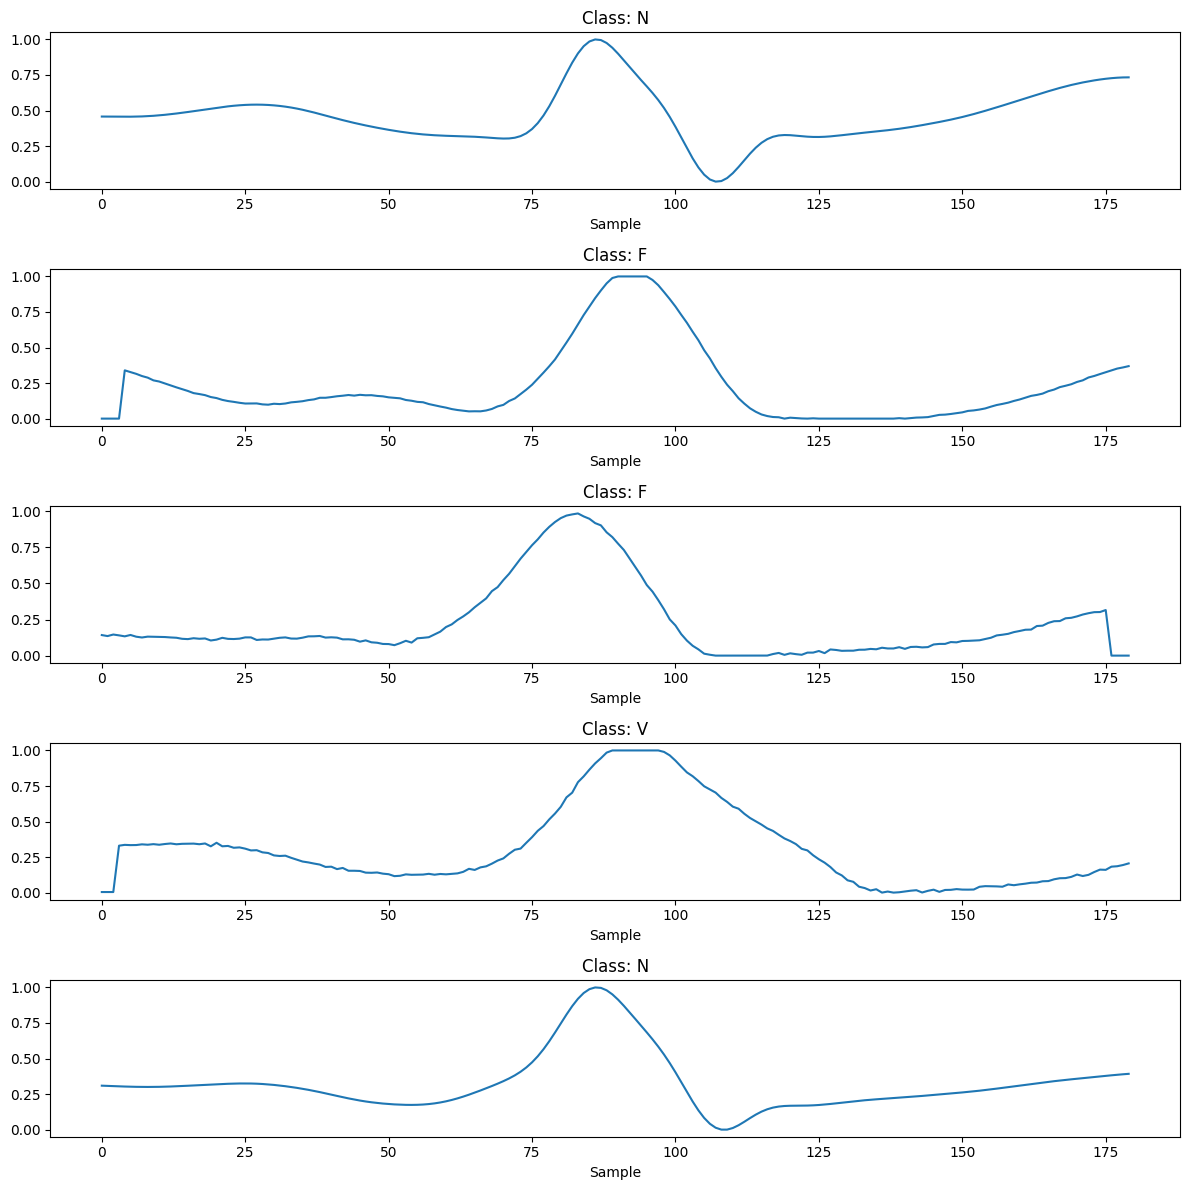

In [ ]:
# ==========================================
# V2 - VISUALIZE BALANCED BATCH
# ==========================================

fig, axes = plt.subplots(
    5,
    1,
    figsize=(12, 12)
)

for i in range(5):

    axes[i].plot(
        batch_x[i].numpy().squeeze()
    )

    class_id = int(
        batch_y[i].numpy()
    )

    class_name = label_encoder.inverse_transform(
        [class_id]
    )[0]

    axes[i].set_title(
        f"Class: {class_name}"
    )

    axes[i].set_xlabel(
        "Sample"
    )

plt.tight_layout()
plt.show()

## 26. Prepare the validation dataset

Creates a TensorFlow dataset from the validation features and labels, batches 256 examples at a time, and prefetches data for efficient evaluation during training. Validation data is not passed through the training augmentation pipeline.


In [ ]:
# ==========================================
# V2 - VALIDATION DATASET
# ==========================================

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_val,
        y_val
    )
)

validation_dataset = validation_dataset.batch(
    256
)

validation_dataset = validation_dataset.prefetch(
    tf.data.AUTOTUNE
)

## 27. Build the CNN-LSTM model

Defines a neural network that accepts a `(180, 1)` ECG beat. The Conv1D blocks learn local waveform patterns; batch normalization and ReLU support training; max pooling reduces the time dimension. Two LSTM layers learn temporal relationships, followed by dense layers and dropout. The five-unit softmax output produces one probability per class. `model_v2.summary()` displays the architecture and parameter counts.


In [ ]:
# ==========================================
# V2 - CNN + LSTM MODEL
# ==========================================

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)

inputs = Input(
    shape=(180, 1),
    name="ECG_Input"
)

# ==========================================
# CNN FEATURE EXTRACTION
# ==========================================

x = Conv1D(
    filters=32,
    kernel_size=5,
    padding='same',
    name="Conv1"
)(inputs)

x = BatchNormalization(
    name="BN1"
)(x)

x = Activation(
    'relu',
    name="ReLU1"
)(x)

x = MaxPooling1D(
    pool_size=2,
    name="Pool1"
)(x)


x = Conv1D(
    filters=64,
    kernel_size=5,
    padding='same',
    name="Conv2"
)(x)

x = BatchNormalization(
    name="BN2"
)(x)

x = Activation(
    'relu',
    name="ReLU2"
)(x)

x = MaxPooling1D(
    pool_size=2,
    name="Pool2"
)(x)


x = Conv1D(
    filters=64,
    kernel_size=3,
    padding='same',
    name="Conv3"
)(x)

x = BatchNormalization(
    name="BN3"
)(x)

x = Activation(
    'relu',
    name="ReLU3"
)(x)


# ==========================================
# LSTM
# ==========================================

x = LSTM(
    128,
    return_sequences=True,
    dropout=0.20,
    recurrent_dropout=0.0,
    name="LSTM1"
)(x)

x = LSTM(
    128,
    return_sequences=False,
    dropout=0.20,
    recurrent_dropout=0.0,
    name="LSTM2"
)(x)


# ==========================================
# DENSE CLASSIFIER
# ==========================================

x = Dense(
    64,
    activation='relu',
    name="Dense1"
)(x)

x = Dropout(
    0.30,
    name="Dropout"
)(x)

x = Dense(
    64,
    activation='relu',
    name="Dense2"
)(x)

outputs = Dense(
    5,
    activation='softmax',
    name="Output"
)(x)

model_v2 = Model(
    inputs=inputs,
    outputs=outputs,
    name="RMS_CNN_LSTM_V2"
)

model_v2.summary()

Model: "RMS_CNN_LSTM_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ECG_Input (InputLayer)          │ (None, 180, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1 (Conv1D)                  │ (None, 180, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN1 (BatchNormalization)        │ (None, 180, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU1 (Activation)              │ (None, 180, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool1 (MaxPooling1D)            │ (None, 90, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv1D)                  │ (None, 90, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN2 (BatchNormalization)        │ (None, 90, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU2 (Activation)              │ (None, 90, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool2 (MaxPooling1D)            │ (None, 45, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv1D)                  │ (None, 45, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN3 (BatchNormalization)        │ (None, 45, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU3 (Activation)              │ (None, 45, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM1 (LSTM)                    │ (None, 45, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM2 (LSTM)                    │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense1 (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense2 (Dense)                  │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,629 (1.02 MB)

 Trainable params: 266,309 (1.02 MB)

 Non-trainable params: 320 (1.25 KB)

## 28. Compile the model

Configures Adam with learning rate 0.001, sparse categorical cross-entropy for integer class labels, and accuracy as the training/validation metric. Compilation prepares the model for `fit`; it does not train the model yet.


In [ ]:
# ==========================================
# V2 - COMPILE
# ==========================================

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("V2 model compiled.")

V2 model compiled.


## 29. Configure training callbacks

Defines three callbacks: early stopping halts training if validation accuracy fails to improve for 10 epochs and restores the best weights; learning-rate reduction halves the rate after four epochs without validation-loss improvement, down to 1e-6; and model checkpointing saves the best model by validation accuracy to `RMS_CNN_LSTM_V2_best.keras`.


In [ ]:
# ==========================================
# V2 - CALLBACKS
# ==========================================

callbacks_v2 = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        mode='max',
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "RMS_CNN_LSTM_V2_best.keras",
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

## 30. Calculate steps per epoch

Sets the intended number of sampled examples per class per epoch and calculates the number of batches needed across all five classes. Because the training dataset repeats indefinitely, `steps_per_epoch` tells Keras when one epoch is considered complete. Integer division may mean the effective total is rounded down to a whole batch.


In [ ]:
# ==========================================
# V2 - TRAINING STEPS
# ==========================================

SAMPLES_PER_CLASS_PER_EPOCH = 20000

STEPS_PER_EPOCH = (
    SAMPLES_PER_CLASS_PER_EPOCH *
    NUM_CLASSES
) // BATCH_SIZE

print(
    "Samples per class per epoch:",
    SAMPLES_PER_CLASS_PER_EPOCH
)

print(
    "Steps per epoch:",
    STEPS_PER_EPOCH
)

Samples per class per epoch: 20000
Steps per epoch: 3125


## 31. Train the CNN-LSTM model

Calls `model_v2.fit` on the balanced, augmented training stream, validates on the separate validation dataset, and allows up to 60 epochs. The callbacks can stop training early, adjust the learning rate, and save the best validation-accuracy checkpoint. The returned `history_v2` stores the recorded metrics for plotting.


In [ ]:
# ==========================================
# V2 - TRAIN
# ==========================================

history_v2 = model_v2.fit(

    balanced_train,

    steps_per_epoch=STEPS_PER_EPOCH,

    validation_data=validation_dataset,

    epochs=60,

    callbacks=callbacks_v2,

    verbose=1
)

Epoch 1/60
3124/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7638 - loss: 0.6552
Epoch 1: val_accuracy improved from None to 0.29277, saving model to RMS_CNN_LSTM_V2_best.keras

Epoch 1: finished saving model to RMS_CNN_LSTM_V2_best.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 81s 24ms/step - accuracy: 0.8569 - loss: 0.4160 - val_accuracy: 0.2928 - val_loss: 4.9953 - learning_rate: 0.0010
Epoch 2/60
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9374 - loss: 0.1920
Epoch 2: val_accuracy improved from 0.29277 to 0.88613, saving model to RMS_CNN_LSTM_V2_best.keras

Epoch 2: finished saving model to RMS_CNN_LSTM_V2_best.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 64s 21ms/step - accuracy: 0.9456 - loss: 0.1661 - val_accuracy: 0.8861 - val_loss: 0.6390 - learning_rate: 0.0010
Epoch 3/60
3124/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9606 - loss: 0.1240
Epoch 3: val_accuracy did not improve from 0.88613
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 62s 20ms/step - accuracy: 0.9644 - loss: 0

## 32. Plot training and validation accuracy

Plots accuracy across epochs for both the training stream and validation set. The dashed 98% line is a visual target only; it does not establish that the model achieved that level or generalizes to unseen records.


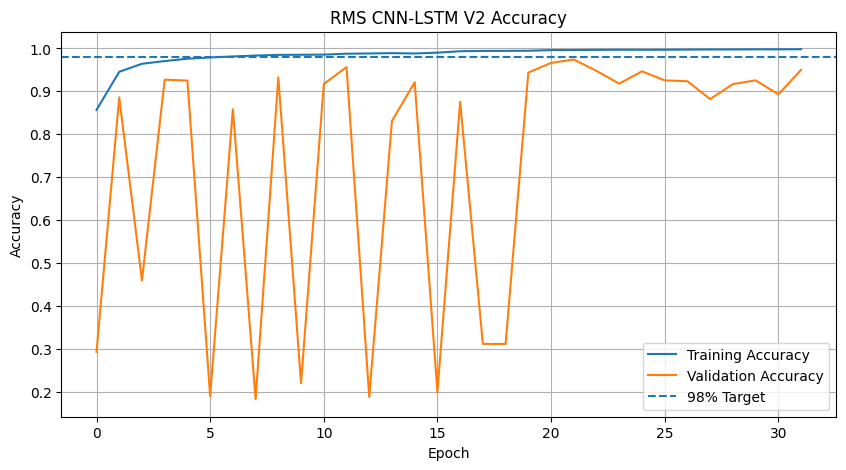

In [ ]:
# ==========================================
# V2 - ACCURACY
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_v2.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_v2.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.axhline(
    0.98,
    linestyle='--',
    label='98% Target'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "RMS CNN-LSTM V2 Accuracy"
)

plt.legend()
plt.grid()

plt.show()

## 33. Plot training and validation loss

Plots the loss values recorded during training and validation. If training loss continues to fall while validation loss rises, that can indicate overfitting; interpret the curves alongside the accuracy plots and test metrics.


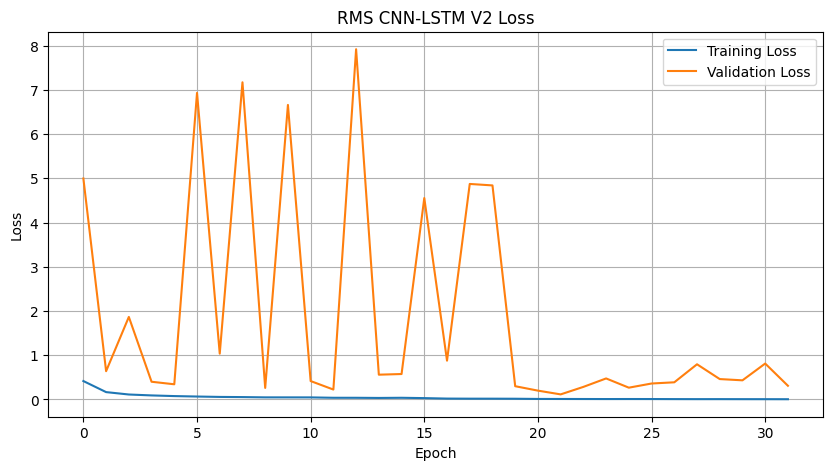

In [ ]:
# ==========================================
# V2 - LOSS
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_v2.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_v2.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "RMS CNN-LSTM V2 Loss"
)

plt.legend()
plt.grid()

plt.show()

## 34. Evaluate on the held-out test set

Evaluates the current in-memory model on `X_test` and `y_test`, returning test loss and test accuracy. The test set should be used for final evaluation rather than tuning repeated model decisions. This evaluation is separate from the validation-based checkpoint selection.


In [ ]:
# ==========================================
# V2 - TEST
# ==========================================

test_loss_v2, test_accuracy_v2 = model_v2.evaluate(
    X_test,
    y_test,
    batch_size=256,
    verbose=1
)

print()
print("====================================")
print("V2 FINAL TEST RESULT")
print("====================================")

print(
    f"Test Accuracy: "
    f"{test_accuracy_v2 * 100:.2f}%"
)

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9764 - loss: 0.1025

V2 FINAL TEST RESULT
Test Accuracy: 97.64%


## 35. Generate test-set predictions

Runs inference on the test examples to obtain a five-column probability vector for each beat. `argmax(axis=1)` selects the index of the largest probability as the predicted integer class ID, producing `y_pred_v2` for metrics and reports.


In [ ]:
# ==========================================
# V2 - PREDICTIONS
# ==========================================

y_prob_v2 = model_v2.predict(
    X_test,
    batch_size=256,
    verbose=1
)

y_pred_v2 = np.argmax(
    y_prob_v2,
    axis=1
)

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


## 36. Print the classification report

Imports the metrics used in later evaluation and prints per-class precision, recall, F1-score, and support, along with aggregate rows. `target_names=label_encoder.classes_` labels the integer classes using the fitted encoder's class order; `digits=4` controls display precision.


In [ ]:
# ==========================================
# V2 - CLASSIFICATION REPORT
# ==========================================

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print(
    classification_report(
        y_test,
        y_pred_v2,
        target_names=label_encoder.classes_,
        digits=4
    )
)

              precision    recall  f1-score   support

           F     0.8477    0.7950    0.8205       161
           N     0.9747    0.9987    0.9866     18122
           Q     0.9962    0.9745    0.9852      1608
           S     0.9839    0.6583    0.7888       556
           V     0.9910    0.8417    0.9103      1447

    accuracy                         0.9764     21894
   macro avg     0.9587    0.8537    0.8983     21894
weighted avg     0.9766    0.9764    0.9752     21894



## 37. Calculate the RMS V2 summary metrics

Calculates overall accuracy and precision, recall, and F1 summaries from the true test labels (`y_test`) and predicted labels (`y_pred_v2`). Macro averages give each class equal weight; weighted F1 weights each class by its number of true examples. `zero_division=0` returns zero for undefined precision/recall cases rather than raising a warning. The printed values are formatted as percentages. These are test-set metrics for this particular split, not proof of record-independent or clinical performance.


In [ ]:
# ==========================================
# V2 - RMS METRICS
# ==========================================

accuracy_v2 = accuracy_score(
    y_test,
    y_pred_v2
)

precision_v2 = precision_score(
    y_test,
    y_pred_v2,
    average='macro',
    zero_division=0
)

recall_v2 = recall_score(
    y_test,
    y_pred_v2,
    average='macro',
    zero_division=0
)

f1_v2 = f1_score(
    y_test,
    y_pred_v2,
    average='macro',
    zero_division=0
)

weighted_f1_v2 = f1_score(
    y_test,
    y_pred_v2,
    average='weighted',
    zero_division=0
)

print("====================================")
print("RMS V2 PERFORMANCE")
print("====================================")

print(
    f"Accuracy        : {accuracy_v2 * 100:.2f}%"
)

print(
    f"Macro Precision : {precision_v2 * 100:.2f}%"
)

print(
    f"Macro Recall    : {recall_v2 * 100:.2f}%"
)

print(
    f"Macro F1        : {f1_v2 * 100:.2f}%"
)

print(
    f"Weighted F1     : {weighted_f1_v2 * 100:.2f}%"
)

RMS V2 PERFORMANCE
Accuracy        : 97.64%
Macro Precision : 95.87%
Macro Recall    : 85.37%
Macro F1        : 89.83%
Weighted F1     : 97.52%
